# Partie 3. VaR, TVaR et modèle collectif

Calculer la VaR et la TVaR dans tous les cas (continu, discret, données, modèle collectif), et tout vérifier par simulation.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Les fonctions de la Partie 3
Exécutez cette cellule en premier : les autres l'utilisent.

In [2]:
def var_discrete(valeurs, probas, alpha):
    """VaR d'une loi discrete : premiere valeur ou F >= alpha."""
    valeurs = np.asarray(valeurs, float); F = np.cumsum(probas)
    return valeurs[np.argmax(F >= alpha - 1e-12)]

def tvar_discrete(valeurs, probas, alpha):
    """TVaR, formule 3 (cas general)."""
    valeurs, probas = np.asarray(valeurs, float), np.asarray(probas, float)
    F = np.cumsum(probas); i = np.argmax(F >= alpha - 1e-12); v = valeurs[i]
    au_dela = valeurs > v
    return (np.sum(valeurs[au_dela] * probas[au_dela]) + v * (F[i] - alpha)) / (1 - alpha)

def tvar_continue(loi, alpha):
    """TVaR, formule 1 : VaR + integrale de S au-dela de la VaR / (1 - alpha)."""
    v = loi.ppf(alpha); queue, _ = integrate.quad(loi.sf, v, np.inf)
    return v + queue / (1 - alpha)

def tvar_empirique(x, alpha):
    x = np.sort(np.asarray(x, float)); n = len(x)
    return tvar_discrete(x, np.full(n, 1 / n), alpha)

def panjer_poisson(lam, fx, smax):
    """Loi exacte de S (Poisson composee), severite entiere fx[j] = P(X = j)."""
    fx = np.asarray(fx, float); fs = np.zeros(smax + 1)
    fs[0] = np.exp(-lam * (1 - fx[0]))
    for s in range(1, smax + 1):
        j = np.arange(1, min(s, len(fx) - 1) + 1)
        fs[s] = lam / s * np.sum(j * fx[j] * fs[s - j])
    return fs

## Chapitre 8. Pourquoi la moyenne ne suffit pas

In [3]:
vA, pA = [100], [1.0]
vB, pB = [0, 10_000], [0.99, 0.01]
for a in [0.98, 0.995]:
    print(f'alpha={a}: VaR A={var_discrete(vA,pA,a):.0f}, VaR B={var_discrete(vB,pB,a):.0f}, TVaR B={tvar_discrete(vB,pB,a):.0f}')

alpha=0.98: VaR A=100, VaR B=0, TVaR B=5000
alpha=0.995: VaR A=100, VaR B=10000, TVaR B=10000


## Chapitre 9. VaR et TVaR des lois continues
Formules fermées et formule 1 (intégrale de S) doivent coïncider.

In [4]:
a = 0.99
lois = {'Exponentielle (moy. 1000)': stats.expon(scale=1000),
        'Normale (-2, 10)': stats.norm(loc=-2, scale=10),
        'Pareto (xm=600, a=2.5)': stats.pareto(b=2.5, scale=600),
        'Lognormale (0, 1)': stats.lognorm(s=1)}
for nom, loi in lois.items():
    print(f'{nom:28s} VaR = {loi.ppf(a):10.2f}   TVaR = {tvar_continue(loi, a):10.2f}')

z = stats.norm.ppf(a)
print('Formules fermees : expo', 1000*np.log(100) + 1000, '| normale', -2 + 10*stats.norm.pdf(z)/(1-a),
      '| Pareto', 2.5/1.5 * 600*(1-a)**(-1/2.5))

Exponentielle (moy. 1000)    VaR =    4605.17   TVaR =    5605.17
Normale (-2, 10)             VaR =      21.26   TVaR =      24.65
Pareto (xm=600, a=2.5)       VaR =    3785.74   TVaR =    6309.57
Lognormale (0, 1)            VaR =      10.24   TVaR =      15.23
Formules fermees : expo 5605.170185988091 | normale 24.652142203458055 | Pareto 6309.573444801931


### Table des z_α et des coefficients de TVaR normale

In [5]:
for a in [0.90, 0.95, 0.975, 0.99, 0.995]:
    z = stats.norm.ppf(a)
    print(f'alpha={a:<6} z={z:.4f}  phi(z)/(1-alpha)={stats.norm.pdf(z)/(1-a):.4f}')

alpha=0.9    z=1.2816  phi(z)/(1-alpha)=1.7550
alpha=0.95   z=1.6449  phi(z)/(1-alpha)=2.0627
alpha=0.975  z=1.9600  phi(z)/(1-alpha)=2.3378
alpha=0.99   z=2.3263  phi(z)/(1-alpha)=2.6652
alpha=0.995  z=2.5758  phi(z)/(1-alpha)=2.8919


### Visualiser la VaR et la TVaR sur la densité

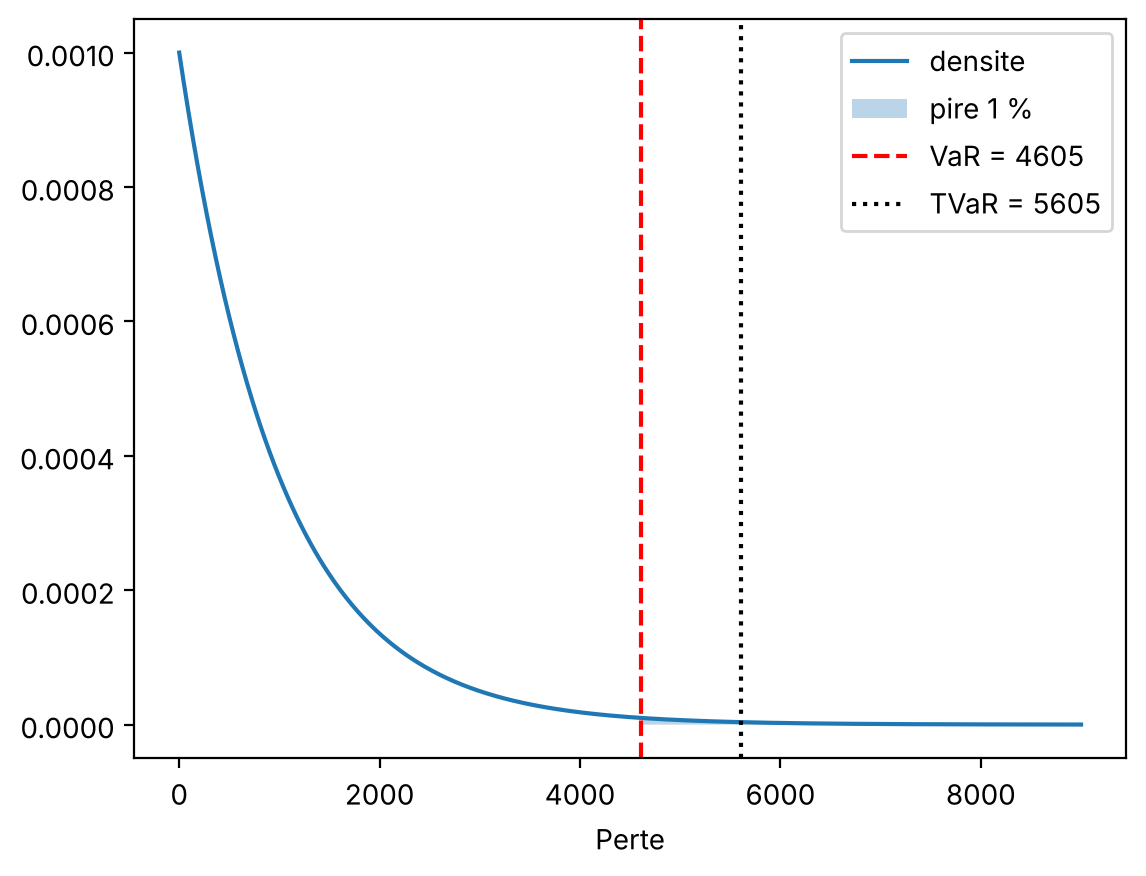

In [6]:
X = stats.expon(scale=1000); a = 0.99
v, t = X.ppf(a), tvar_continue(X, a)
xs = np.linspace(0, 9000, 600)
plt.plot(xs, X.pdf(xs), label='densite')
plt.fill_between(xs, X.pdf(xs), where=xs >= v, alpha=0.3, label='pire 1 %')
plt.axvline(v, color='red', ls='--', label=f'VaR = {v:.0f}')
plt.axvline(t, color='black', ls=':', label=f'TVaR = {t:.0f}')
plt.xlabel('Perte'); plt.legend(); plt.show()

## Double vérification par simulation

In [7]:
sim = X.rvs(size=1_000_000, random_state=rng)
v_sim = np.quantile(sim, 0.99, method='inverted_cdf')
print('VaR simulee', v_sim, '| TVaR simulee', sim[sim > v_sim].mean())

VaR simulee 4594.075577435081 | TVaR simulee 5609.025419147694


## Cas discret et piège de la CTE (exemple résolu 7)

In [8]:
v, p = [0, 100, 500, 2000], [0.80, 0.15, 0.04, 0.01]
for a in [0.90, 0.95, 0.99, 0.995]:
    print(a, 'VaR =', var_discrete(v, p, a), '| TVaR =', round(tvar_discrete(v, p, a), 2))
vv, pp = np.array(v), np.array(p)
print('CTE 90 % = E[L | L > 100] =', np.sum(vv[vv > 100] * pp[vv > 100]) / np.sum(pp[vv > 100]))

0.9 VaR = 100.0 | TVaR = 450.0
0.95 VaR = 100.0 | TVaR = 800.0
0.99 VaR = 500.0 | TVaR = 2000.0
0.995 VaR = 2000.0 | TVaR = 2000.0
CTE 90 % = E[L | L > 100] = 800.0


## Sur données : VaR et TVaR empiriques

In [9]:
x = [3, 4, 9, 12, 15, 18, 22, 28, 37, 45, 55, 61, 70, 78, 95, 140, 150, 310, 520, 980]
print('VaR 90 % :', np.quantile(x, 0.9, method='inverted_cdf'), '| interpolation par defaut :', np.quantile(x, 0.9))
print('TVaR 90 % :', tvar_empirique(x, 0.9), '| moyenne :', np.mean(x))

VaR 90 % : 310 | interpolation par defaut : 331.0000000000003
TVaR 90 % : 750.0000000000009 | moyenne : 132.6


## Queue fine contre queue lourde (même moyenne 1000)

moyennes : 1000.0 1000.0
0.95: VaR expo     2996 | VaR Pareto     1989 | TVaR expo     3996 | TVaR Pareto     3314
0.99: VaR expo     4605 | VaR Pareto     3786 | TVaR expo     5605 | TVaR Pareto     6310
0.995: VaR expo     5298 | VaR Pareto     4995 | TVaR expo     6298 | TVaR Pareto     8326
0.999: VaR expo     6908 | VaR Pareto     9509 | TVaR expo     7908 | TVaR Pareto    15849


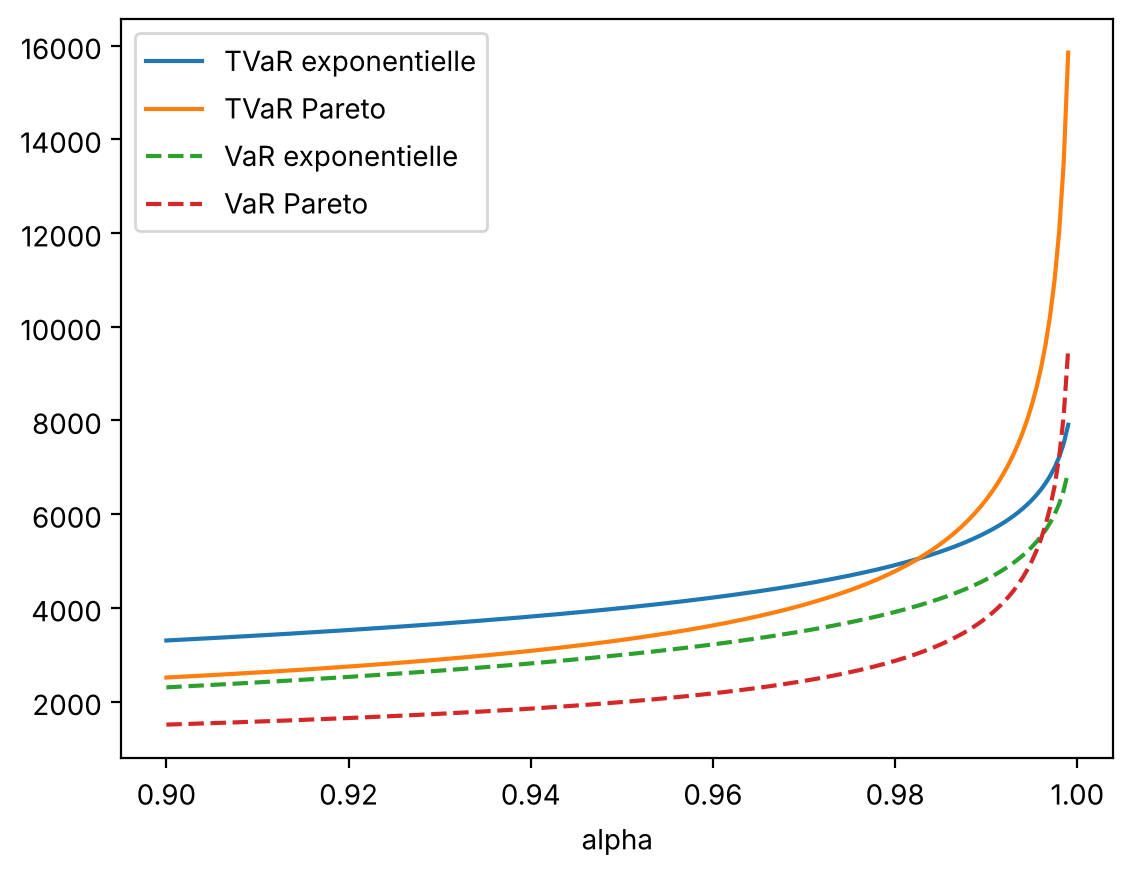

In [10]:
E, P = stats.expon(scale=1000), stats.pareto(b=2.5, scale=600)
print('moyennes :', E.mean(), P.mean())
for a in [0.95, 0.99, 0.995, 0.999]:
    print(f'{a}: VaR expo {E.ppf(a):8.0f} | VaR Pareto {P.ppf(a):8.0f} | TVaR expo {tvar_continue(E,a):8.0f} | TVaR Pareto {tvar_continue(P,a):8.0f}')

al = np.linspace(0.9, 0.999, 200)
plt.plot(al, [tvar_continue(E, a) for a in al], label='TVaR exponentielle')
plt.plot(al, [tvar_continue(P, a) for a in al], label='TVaR Pareto')
plt.plot(al, E.ppf(al), '--', label='VaR exponentielle'); plt.plot(al, P.ppf(al), '--', label='VaR Pareto')
plt.xlabel('alpha'); plt.legend(); plt.show()

## Chapitre 10. La VaR n'est pas sous-additive (exemple 9)

In [11]:
v1, p1 = [0, 100], [0.96, 0.04]
vS, pS = [0, 100, 200], [0.96**2, 2*0.96*0.04, 0.04**2]
print('VaR  :', var_discrete(v1, p1, .95), '+', var_discrete(v1, p1, .95), 'vs portefeuille', var_discrete(vS, pS, .95))
print('TVaR :', tvar_discrete(v1, p1, .95), '+', tvar_discrete(v1, p1, .95), 'vs portefeuille', round(tvar_discrete(vS, pS, .95), 2))

n = 2_000_000
S = 100 * (rng.random(n) < 0.04) + 100 * (rng.random(n) < 0.04)
print('Simulation : VaR 95 % du portefeuille =', np.quantile(S, 0.95, method='inverted_cdf'))

VaR  : 0.0 + 0.0 vs portefeuille 100.0
TVaR : 79.99999999999993 + 79.99999999999993 vs portefeuille 103.2
Simulation : VaR 95 % du portefeuille = 100


### Cas gaussien : gain de diversification selon la corrélation

In [12]:
z = stats.norm.ppf(0.99); sx, sy = 10, 10
for rho in [-0.5, 0, 0.3, 0.5, 1]:
    s = np.sqrt(sx**2 + sy**2 + 2*rho*sx*sy)
    print(f'rho={rho:5}: VaR total={z*s:6.2f}  somme des VaR={z*(sx+sy):6.2f}  gain={z*(sx+sy-s):6.2f}')

rho= -0.5: VaR total= 23.26  somme des VaR= 46.53  gain= 23.26
rho=    0: VaR total= 32.90  somme des VaR= 46.53  gain= 13.63
rho=  0.3: VaR total= 37.51  somme des VaR= 46.53  gain=  9.02
rho=  0.5: VaR total= 40.29  somme des VaR= 46.53  gain=  6.23
rho=    1: VaR total= 46.53  somme des VaR= 46.53  gain=  0.00


## Chapitre 11. Modèle collectif (exemple 10)

E[S] = 25000 | sigma = 5000.0 | VaR 99.5 % normale = 37879.146517744506


Simulation : moyenne 24999.46514333929 | VaR 99.5 % 39245.34834571393 | TVaR 99.5 % 41336.51020593017


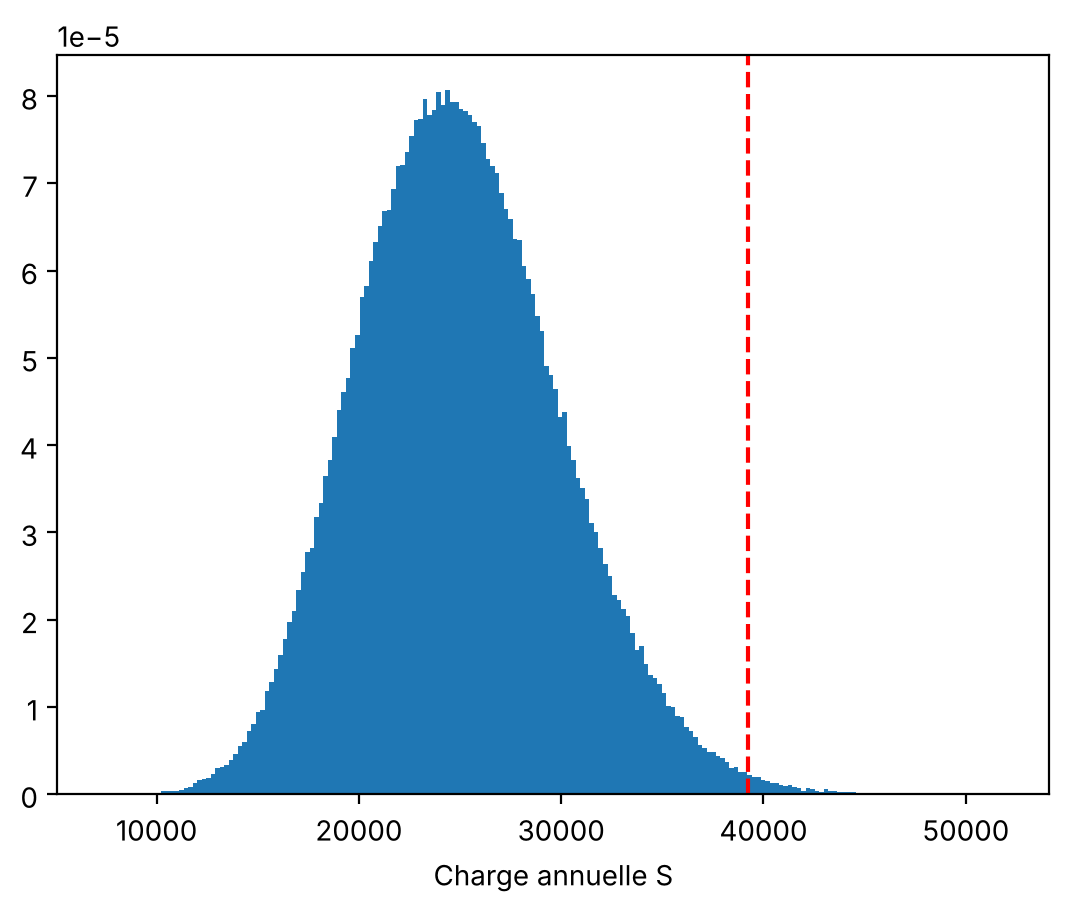

In [13]:
lam, theta = 50, 500
ES, sdS = lam*theta, np.sqrt(lam*2*theta**2)
print('E[S] =', ES, '| sigma =', sdS, '| VaR 99.5 % normale =', ES + stats.norm.ppf(0.995)*sdS)

n_sim = 400_000
N = rng.poisson(lam, size=n_sim)
montants = rng.exponential(theta, size=N.sum())
S = np.bincount(np.repeat(np.arange(n_sim), N), weights=montants, minlength=n_sim)
v = np.quantile(S, 0.995, method='inverted_cdf')
print('Simulation : moyenne', S.mean(), '| VaR 99.5 %', v, '| TVaR 99.5 %', S[S > v].mean())
plt.hist(S, bins=200, density=True); plt.axvline(v, color='red', ls='--'); plt.xlabel('Charge annuelle S'); plt.show()

## Vérification des exercices 8.1 à 11.3

In [14]:
print('8.2 :', -1 + 4*stats.norm.ppf(0.99))
for a in [0.95, 0.99]:
    L = stats.expon(scale=2000); print('9.1', a, L.ppf(a), tvar_continue(L, a))
v, p = [0, 1000, 5000, 20000], [0.70, 0.20, 0.08, 0.02]
print('9.2 VaR :', [var_discrete(v, p, a) for a in [.90, .95, .98, .99]], '| TVaR 95 % :', tvar_discrete(v, p, .95))
U = stats.uniform(scale=10); print('9.3 (b=10, alpha=0.9) :', U.ppf(.9), tvar_continue(U, .9), '= (1+0.9)*10/2')
L = stats.norm(5, 20); print('9.4 :', L.ppf(.975), tvar_continue(L, .975))
d = [5, 12, 7, 30, 18, 2, 45, 9, 15, 60]
print('9.5 :', np.quantile(d, .8, method='inverted_cdf'), tvar_empirique(d, .8), tvar_empirique(d, .75))
M1, M2 = stats.pareto(b=3, scale=1000), stats.expon(scale=1500)
for a in [.99, .999]:
    print('9.6', a, 'Pareto', M1.ppf(a), tvar_continue(M1, a), '| expo', M2.ppf(a), tvar_continue(M2, a))
print('10.1 :', 2*stats.expon(scale=1000).ppf(.99) + 500, 2*tvar_continue(stats.expon(scale=1000), .99) + 500)
z = stats.norm.ppf(.99)
for rho in [0.5, -0.5]:
    s = np.sqrt(100 + 400 + 2*rho*200); print('10.2 rho', rho, z*s, z*30 - z*s)
print('10.3 :', var_discrete([0,1000],[.97,.03],.95), tvar_discrete([0,1000],[.97,.03],.95),
      var_discrete([0,1000,2000],[.97**2,2*.97*.03,.03**2],.95), round(tvar_discrete([0,1000,2000],[.97**2,2*.97*.03,.03**2],.95), 2))
print('11.1 :', 20*1000, 20*2*1000**2, np.sqrt(20*2*1000**2))
print('11.2 :', 10*2000, np.sqrt(10*1000**2 + 15*2000**2))
fx = np.zeros(6); fx[1], fx[5] = 0.7, 0.3
fs = panjer_poisson(10, fx, 200); val = np.arange(201) * 1000
print('11.3 normale :', 22000 + z*np.sqrt(82e6))
for a in [0.95, 0.99, 0.995]:
    print('11.3 Panjer', a, var_discrete(val, fs, a), round(tvar_discrete(val, fs, a), 1))

8.2 : 8.305391496163363


9.1 0.95 5991.46454710798 7991.46454710798
9.1 0.99 9210.340371976183 11210.34037197618
9.2 VaR : [np.float64(1000.0), np.float64(5000.0), np.float64(5000.0), np.float64(20000.0)] | TVaR 95 % : 10999.999999999982
9.3 (b=10, alpha=0.9) : 9.0 9.5 = (1+0.9)*10/2
9.4 : 44.19927969080108 51.75605584402844
9.5 : 30 52.49999999999999 47.99999999999999
9.6 0.99 Pareto 4641.588833612776 6962.383250419167 | expo 6907.755278982137 8407.755278982133


9.6 0.999 Pareto 9999.999999999996 14999.999999999996 | expo 10361.632918473204 11861.632918473202
10.1 : 9710.340371976183 11710.34037197618
10.2 rho 0.5 61.549379377358775 8.241056843866446
10.2 rho -0.5 40.29352713918579 29.49690908203943
10.3 : 0.0 599.9999999999994 1000.0 1018.0
11.1 : 20000 40000000 6324.555320336759
11.2 : 20000 8366.600265340756
11.3 normale : 43065.975964727004
11.3 Panjer 0.95 38000.0 43109.4
11.3 Panjer 0.99 46000.0 50545.9
11.3 Panjer 0.995 49000.0 53476.1
